# 02 · Feature engineering: from transactions to users

A model sees one row at a time. Fraud, however, is a property of a **user or card**:
once a card is compromised, the fraudster uses it repeatedly, and Vesta's labels follow
the user (notebook 01). The single most valuable step on this dataset is to give each row
a memory of the user's **past**.

Plan:
1. Rebuild a **user ID** from card, address and account-opening date.
2. Engineer feature groups: amounts, time, frequency encodings, user history, and the
   user's previously confirmed frauds under a realistic **label delay**.
3. Measure each group's contribution with an **ablation study**: add groups one at a
   time and score the next month.
4. Show what **leakage** looks like, using a tempting but invalid feature set.

Every feature here is **causal**: computed only from information available at the
moment the transaction is scored.

In [1]:
import time
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from sklearn.metrics import average_precision_score, roc_auc_score

from fraudkit import ieee
from fraudkit.data import load_ieee, prepare_ieee
from fraudkit.metrics import bootstrap_ci, paired_bootstrap_diff
from fraudkit.plotting import CLASS_COLORS, INK_2, MUTED, SERIES, finish, label_bars, set_style

set_style()
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
warnings.filterwarnings("ignore", message="X does not have valid feature names")
pd.set_option("display.float_format", "{:,.4f}".format)
TRAIN_END, VAL_END = 120, 150

# Load everything except the redundant V columns (notebook 01), to save memory.
paths = prepare_ieee()
tx_cols = pq.read_schema(paths["train_transaction"]).names
id_cols = pq.read_schema(paths["train_identity"]).names
v_cols = [c for c in tx_cols if c.startswith("V")]
keep_v = ieee.select_v_columns(load_ieee(v_cols, identity=False))
ieee.release_memory()   # return the temporary V-column frame's memory to the OS
df = load_ieee([c for c in tx_cols if c not in v_cols] + keep_v + id_cols)
RAW = [c for c in df.columns if c not in ("TransactionID", "TransactionDT", "isFraud")]
df = ieee.add_time_features(df)
train_mask = (df.day < TRAIN_END).values
val_mask = ((df.day >= TRAIN_END) & (df.day < VAL_END)).values
print(df.shape, f"{df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

(590540, 228) 0.49 GB


## 1. Reconstructing users

The data has no customer ID, but the pieces of one are there:
* `card1`: a card code (13,553 distinct values: too coarse on its own),
* `addr1`: billing region,
* `D1`: days since the card was first seen. **day − D1** is the card's first-seen date,
  constant for the card's whole life (notebook 01, section 6).

Together they form a **user ID** proxy (`uid`). Rows missing any part get "unknown user".

In [2]:
df = ieee.add_uid(df)
known = df.uid >= 0
sizes = df.loc[known, "uid"].value_counts()
print(f"rows with a uid: {known.mean():.1%}   distinct users: {len(sizes):,}")
print(f"rows belonging to users with 2+ transactions: {(df.loc[known, 'uid'].map(sizes) > 1).mean():.1%}")

rows with a uid: 88.7%   distinct users: 199,070
rows belonging to users with 2+ transactions: 77.9%


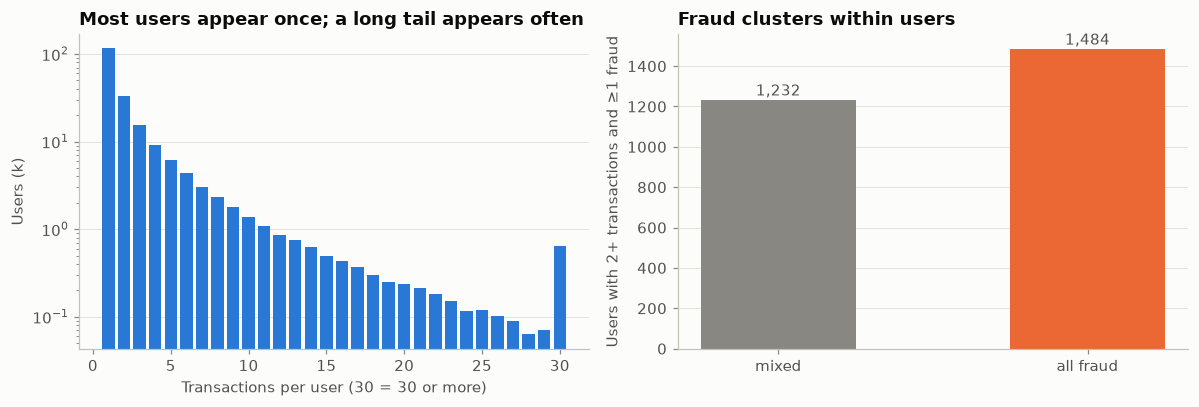

In [3]:
g = df[known].groupby("uid").isFraud
n_tx, fraud_share = g.size(), g.mean()
multi = n_tx >= 2
cats = pd.cut(fraud_share[multi], [-0.01, 0, 0.999, 1], labels=["all legit", "mixed", "all fraud"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
counts = n_tx.clip(upper=30).value_counts().sort_index()
ax.bar(counts.index, counts.values / 1000, color=SERIES[0], width=0.8)
ax.set_xlabel("Transactions per user (30 = 30 or more)"); ax.set_ylabel("Users (k)")
ax.set_yscale("log"); ax.set_title("Most users appear once; a long tail appears often")
ax = axes[1]
fraud_users = cats[fraud_share[multi] > 0].value_counts().reindex(["mixed", "all fraud"])
bars = ax.bar(fraud_users.index, fraud_users.values, color=[MUTED, CLASS_COLORS[1]], width=0.5)
label_bars(ax, bars, fmt="{:,.0f}")
ax.set_ylabel("Users with 2+ transactions and ≥1 fraud")
ax.set_title("Fraud clusters within users")
for a in axes:
    a.grid(axis="x", visible=False)
finish(fig)

**Reading it.** The proxy finds ~199,000 users. Most appear once, but 78 % of the
transactions with a known user belong to users who appear at least twice, so most rows
*have* a history to learn from. Among repeat users with any fraud, more are **entirely
fraudulent** (1,484) than mixed (1,232). Fraud clusters within users, as Vesta's
labelling rule predicts.

## 2. Feature groups

| Group | Features | Idea |
|---|---|---|
| **Amount** | log amount, cents, odd-decimals flag | currency conversion and price-point signals (notebook 01) |
| **Time** | hour of day, weekday | behavioural rhythm; fraud peaks at odd hours |
| **Frequency** | how often each card/address/e-mail/device value appeared in training | rare values are riskier; lets trees use high-cardinality IDs |
| **User history** | transactions so far, time since previous, amount vs. the user's mean, activity in last 24 h / 7 days, distinct e-mails and devices | the user's normal behaviour, and deviations from it |
| **Confirmed fraud** | number of the user's earlier frauds *whose label had already arrived* | fraud repeats within users |

**Frequency encoding** is fitted on the training period only. Counting over all rows
would let validation-period volumes leak into the features.

In [4]:
df = ieee.add_amount_features(df)
FREQ_COLS = ["card1", "card2", "card3", "card5", "addr1", "P_emaildomain", "R_emaildomain", "DeviceInfo", "id_31"]
df = ieee.frequency_encode(df, FREQ_COLS, fit_mask=train_mask)
df = ieee.causal_uid_features(df)

# Normalised D columns as *extra* columns; each experiment chooses raw or normalised.
day = np.floor(df.TransactionDT / ieee.DAY)
for c in ieee.D_DAYS_SINCE:
    df[f"{c}n"] = (day - df[c]).astype("float32")

### Confirmed fraud under label delay

The strongest signal is that a user committed fraud before. But labels arrive late:
a chargeback can take weeks, and Vesta waited up to 120 days. A feature that uses a
label before it would really be known is **leakage**. It looks great offline and fails
in production.

`prior_fraud_count(df, delay)` counts the user's earlier frauds whose label would have
arrived by now, assuming each label takes `delay` days.

In [5]:
DELAYS = [0, 7, 30, 60]
for d in DELAYS:
    df[f"prior_fraud_{d}d"] = ieee.prior_fraud_count(df, d)

has_prior = pd.DataFrame({
    f"{d} days": [(df.loc[df.isFraud == 1, f"prior_fraud_{d}d"] > 0).mean(),
                  (df.loc[df.isFraud == 0, f"prior_fraud_{d}d"] > 0).mean()] for d in DELAYS
}, index=["frauds with a known earlier fraud", "legit with a known earlier fraud"])
has_prior

,0 days,7 days,30 days,60 days
frauds with a known earlier fraud,0.3904,0.1854,0.1026,0.0591
legit with a known earlier fraud,0.0073,0.0032,0.0020,0.0012


**Reading it.** With instant labels, 39 % of frauds come from a user with an
already-confirmed fraud, against 0.7 % of legit transactions. A 30-day delay cuts the
coverage to 10 % of frauds, but the contrast remains about 50 to 1. The feature fires
rarely, but when it fires it is nearly decisive.

## 3. Ablation study

We train the same LightGBM on growing feature sets: train on months 1–4, score month 5
(validation). Hyperparameters are fixed and moderate, so differences come from the
features. Month 6 stays untouched for notebook 03.

Two sources of noise blur small differences: *which rows* happen to be in the validation
month, and *training randomness* (LightGBM samples rows and columns). Each configuration
is therefore trained with three random seeds and their predictions are averaged.

In [6]:
base_raw = RAW   # every original column (minus redundant V), D columns as raw "days since"
amount_time = ["amt_log", "amt_cents", "amt_odd_decimals", "hour", "weekday"]
freq = [f"{c}_freq" for c in FREQ_COLS]
d_raw = [c for c in ieee.D_DAYS_SINCE]
d_norm = [f"{c}n" for c in ieee.D_DAYS_SINCE]
history = [c for c in df.columns if c.startswith("uid_") or c == "amt_vs_uid_mean"]

raw_dnorm = [c for c in base_raw if c not in d_raw] + d_norm
experiments = {
    "1 raw columns": base_raw,
    "2 + amount & time": base_raw + amount_time,
    "3 + frequency enc.": base_raw + amount_time + freq,
    "4 D normalised": raw_dnorm + amount_time + freq,
    "5 + user history": raw_dnorm + amount_time + freq + history,
    "6 + confirmed fraud (30 d)": raw_dnorm + amount_time + freq + history + ["prior_fraud_30d"],
}

# The leaky features of section 5 are computed now, so that everything can be packed into
# compact float32 matrices once and the DataFrame freed. On a 7 GB machine, handing
# LightGBM pandas slices would create float64 copies and run out of memory.
leaky = ieee.transductive_uid_features(df)
for c in leaky:
    df[c] = leaky[c]
ALL = list(dict.fromkeys(sum(experiments.values(), []) + [f"prior_fraud_{d}d" for d in DELAYS] + list(leaky.columns)))
X_tr, cat_pos = ieee.to_float32(df, ALL, rows=train_mask)
X_va, _ = ieee.to_float32(df, ALL, rows=val_mask)
CATS = {ALL[i] for i in cat_pos}
COL = {c: i for i, c in enumerate(ALL)}
y = df.isFraud.values
meta = df[["uid", "day", "isFraud"]].copy()
del df, leaky
ieee.release_memory()
print(f"train matrix {X_tr.shape}, {X_tr.nbytes / 1e9:.2f} GB; validation {X_va.shape}")

PARAMS = dict(n_estimators=600, learning_rate=0.05, num_leaves=127, min_child_samples=100,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=1.0,
              max_cat_to_onehot=8, cat_smooth=20, random_state=0, verbose=-1, n_jobs=12)
results, models, val_scores = {}, {}, {}
SEEDS = (0, 1, 2)


def run(name, features):
    """Train with 3 random seeds. LightGBM subsamples rows and columns, so a single run's
    score includes training luck; averaging the seeds' predictions removes most of it, and
    the spread across seeds shows how big that luck is."""
    t = time.time()
    idx = [COL[c] for c in features]
    cats = [i for i, c in enumerate(features) if c in CATS]
    preds, seed_scores = [], []
    for seed in SEEDS:
        m = lgb.LGBMClassifier(**{**PARAMS, "random_state": seed}).fit(
            X_tr[:, idx], y[train_mask], feature_name=features, categorical_feature=cats)
        preds.append(m.predict_proba(X_va[:, idx])[:, 1])
        seed_scores.append(average_precision_score(y[val_mask], preds[-1]))
        if seed == 0:
            models[name] = m
    s = np.mean(preds, axis=0)
    pr, lo, hi = bootstrap_ci(average_precision_score, y[val_mask], s, n_boot=300)
    results[name] = {"features": len(features), "PR-AUC": pr, "lo": lo, "hi": hi,
                     "seed sd": np.std(seed_scores, ddof=1), "ROC-AUC": roc_auc_score(y[val_mask], s),
                     "minutes": (time.time() - t) / 60}
    val_scores[name] = s
    print(f"{name:32s} PR-AUC {pr:.4f} [{lo:.4f}, {hi:.4f}]  single seeds "
          f"{', '.join(f'{v:.4f}' for v in seed_scores)}  ({results[name]['minutes']:.1f} min)")


for name, feats in experiments.items():
    run(name, feats)

train matrix (410601, 266), 0.44 GB; validation (85303, 266)


1 raw columns                    PR-AUC 0.6385 [0.6211, 0.6548]  single seeds 0.6320, 0.6305, 0.6269  (1.3 min)


2 + amount & time                PR-AUC 0.6338 [0.6162, 0.6499]  single seeds 0.6239, 0.6305, 0.6243  (1.3 min)


3 + frequency enc.               PR-AUC 0.6459 [0.6276, 0.6611]  single seeds 0.6360, 0.6398, 0.6386  (1.5 min)


4 D normalised                   PR-AUC 0.6719 [0.6542, 0.6875]  single seeds 0.6640, 0.6640, 0.6614  (1.5 min)


5 + user history                 PR-AUC 0.6657 [0.6482, 0.6804]  single seeds 0.6554, 0.6569, 0.6587  (1.7 min)


6 + confirmed fraud (30 d)       PR-AUC 0.7186 [0.7030, 0.7321]  single seeds 0.7112, 0.7107, 0.7125  (1.5 min)


Each line shows the 3-seed average and the three single-seed scores. Seeds move PR-AUC
by only a few thousandths, so the steps between configurations are mostly real. Section 6
tests each step formally.

## 4. What label delay costs

The confirmed-fraud feature is only as good as the labels behind it. Re-running step 5
with labels arriving after 0, 7, 30 and 60 days shows the value of faster feedback.

In [7]:
best_hist = experiments["5 + user history"]
for d in DELAYS:
    if d != 30:
        run(f"6 + confirmed fraud ({d} d)", best_hist + [f"prior_fraud_{d}d"])

6 + confirmed fraud (0 d)        PR-AUC 0.8418 [0.8313, 0.8511]  single seeds 0.8368, 0.8393, 0.8380  (1.5 min)


6 + confirmed fraud (7 d)        PR-AUC 0.7597 [0.7460, 0.7722]  single seeds 0.7525, 0.7579, 0.7522  (1.5 min)


6 + confirmed fraud (60 d)       PR-AUC 0.7009 [0.6838, 0.7151]  single seeds 0.6943, 0.6925, 0.6927  (1.4 min)


## 5. What leakage looks like

A tempting shortcut is to aggregate over each user's **entire** history: total
transaction count, overall mean amount. Pandas makes it a one-liner
(`groupby("uid").transform("mean")`), and many public Kaggle notebooks did it. But for a
transaction on day 10, it uses amounts from day 170: information that doesn't exist yet.

In [8]:
run("LEAKY: whole-history aggregates",
    raw_dnorm + amount_time + freq + ["uid_n_total", "uid_amt_mean_all", "uid_amt_std_all"])

LEAKY: whole-history aggregates  PR-AUC 0.6939 [0.6767, 0.7083]  single seeds 0.6858, 0.6841, 0.6852  (1.4 min)


**Reading it.** The leaky aggregates score 0.694, against 0.666 for the honest,
past-only user history: a **+0.03 gain that is pure leakage**. Worse, it would have led
to the wrong conclusion. The causal history features turn out to *hurt* slightly
(section 6), while the leaky ones appear to help. In production the future isn't
available, and the score would fall back. Leakage doesn't just inflate numbers; it
corrupts decisions.

### A pruned feature set

Section 6 shows two groups that hurt: amount & time, and user history. Dropping them is
itself a hypothesis, so it gets its own run rather than being assumed.

In [9]:
run("7 pruned (no amount/time, no history)", raw_dnorm + freq + ["prior_fraud_30d"])

7 pruned (no amount/time, no history) PR-AUC 0.7179 [0.7023, 0.7317]  single seeds 0.7123, 0.7131, 0.7089  (1.3 min)


## 6. Results

In [10]:
res = pd.DataFrame(results).T
res

,features,PR-AUC,lo,hi,seed sd,ROC-AUC,minutes
1 raw columns,222.0000,0.6385,0.6211,0.6548,0.0026,0.9326,1.3364
2 + amount & time,227.0000,0.6338,0.6162,0.6499,0.0037,0.9315,1.3361
3 + frequency enc.,236.0000,0.6459,0.6276,0.6611,0.0019,0.9359,1.5348
4 D normalised,236.0000,0.6719,0.6542,0.6875,0.0015,0.9408,1.5390
5 + user history,245.0000,0.6657,0.6482,0.6804,0.0017,0.9404,1.7103
6 + confirmed fraud (30 d),246.0000,0.7186,0.7030,0.7321,0.0009,0.9520,1.5059
6 + confirmed fraud (0 d),246.0000,0.8418,0.8313,0.8511,0.0012,0.9753,1.4794
6 + confirmed fraud (7 d),246.0000,0.7597,0.7460,0.7722,0.0032,0.9611,1.5242
6 + confirmed fraud (60 d),246.0000,0.7009,0.6838,0.7151,0.0010,0.9476,1.3729
LEAKY: whole-history aggregates,239.0000,0.6939,0.6767,0.7083,0.0009,0.9448,1.3524


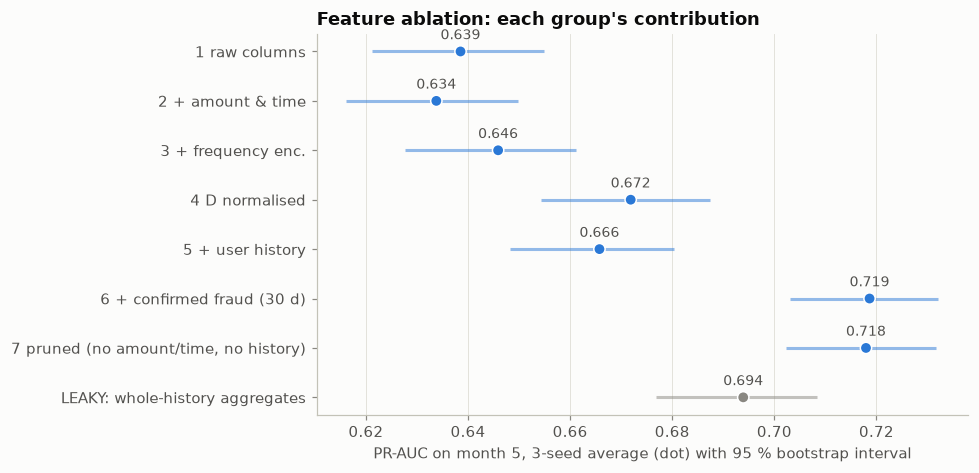

In [11]:
order = ["1 raw columns", "2 + amount & time", "3 + frequency enc.", "4 D normalised",
         "5 + user history", "6 + confirmed fraud (30 d)", "7 pruned (no amount/time, no history)",
         "LEAKY: whole-history aggregates"]
plot = res.loc[order]
fig, ax = plt.subplots(figsize=(9, 4.4))
y_pos = np.arange(len(plot))[::-1]
colors = [SERIES[0]] * 7 + [MUTED]
ax.hlines(y_pos, plot["lo"], plot["hi"], color=colors, lw=2, alpha=0.5)
ax.scatter(plot["PR-AUC"], y_pos, color=colors, s=55, zorder=3, edgecolor="white", linewidth=1)
for yp, v in zip(y_pos, plot["PR-AUC"]):
    ax.annotate(f"{v:.3f}", (v, yp), xytext=(0, 8), textcoords="offset points", ha="center",
                fontsize=9, color=INK_2)
ax.set_yticks(y_pos, plot.index)
ax.set_xlabel("PR-AUC on month 5, 3-seed average (dot) with 95 % bootstrap interval")
ax.set_title("Feature ablation: each group's contribution")
ax.grid(axis="y", visible=False)
finish(fig)

The intervals above describe each model on its own. To judge whether a step *helped*,
we bootstrap the **difference** between consecutive steps, resampling the same rows for
both models. Shared noise cancels, so a real gain of +0.01 can be detected even though
the separate intervals overlap.

In [12]:
y_val = y[val_mask]
steps = order[:6]
gains = pd.DataFrame(
    [dict(zip(["gain", "lo", "hi"], paired_bootstrap_diff(average_precision_score, y_val,
                                                          val_scores[a], val_scores[b], n_boot=300)))
     for a, b in zip(steps, steps[1:])],
    index=steps[1:])
gains["verdict"] = np.where(gains.lo > 0, "helps", np.where(gains.hi < 0, "hurts", "no clear effect"))
pruned_gain = paired_bootstrap_diff(average_precision_score, y_val, val_scores["6 + confirmed fraud (30 d)"],
                                    val_scores["7 pruned (no amount/time, no history)"], n_boot=300)
print(f"pruned vs. step 6: {pruned_gain[0]:+.4f} (95 % CI {pruned_gain[1]:+.4f} to {pruned_gain[2]:+.4f})")
gains

pruned vs. step 6: -0.0007 (95 % CI -0.0037 to +0.0024)


,gain,lo,hi,verdict
2 + amount & time,-0.0047,-0.0082,-0.0018,hurts
3 + frequency enc.,0.0121,0.0090,0.0154,helps
4 D normalised,0.0260,0.0203,0.0316,helps
5 + user history,-0.0061,-0.0091,-0.0033,hurts
6 + confirmed fraud (30 d),0.0529,0.0466,0.0610,helps


**Reading it.** The seed spread (`seed sd` in the results table, at most 0.004) and the
paired intervals agree: these verdicts are not noise.

* **Normalised D columns: +0.026, the biggest classic step.** This is the transformation
  that adversarial validation flagged in notebook 01 for *increasing* drift. Both
  findings are true: the normalised dates do encode the calendar, and they also identify
  accounts and account cohorts, which matters more here. Adversarial validation is a
  warning light. Performance on a later period is the verdict.
* **Frequency encodings: +0.012.** Rare cards, regions and devices are riskier, and the
  counts let trees use high-cardinality IDs sensibly.
* **Amount & time (−0.005) and user history (−0.006) hurt slightly.** Vesta's own columns
  already describe behaviour: `C1`–`C14` are counts linked to the card, `D3` is days since
  the previous transaction, and many V columns are sums and counts over time windows.
  Our versions are largely redundant. With `colsample_bytree=0.5`, each tree sees half the
  columns, so redundant ones crowd out stronger ones. A sensible idea can still be
  redundant, and only measurement tells.
* **Confirmed fraud (30-day delay): +0.053**, by far the largest step.
* **The pruned set ties step 6** (−0.001, interval −0.004 to +0.002). Dropping the two
  redundant groups doesn't win back the +0.011 their individual effects would suggest.
  Feature effects aren't additive: once confirmed fraud is in, the history features no
  longer matter either way. Same accuracy with 14 fewer features and less code to
  maintain, so the pruned set goes forward.

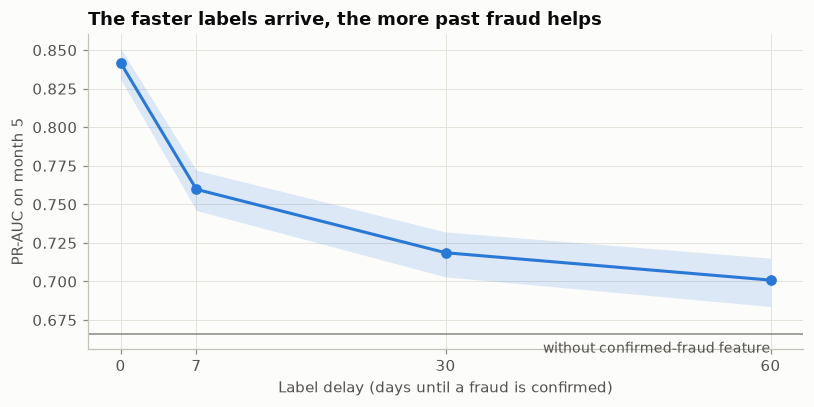

In [13]:
delay_names = [f"6 + confirmed fraud ({d} d)" for d in DELAYS]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(DELAYS, res.loc[delay_names, "PR-AUC"], marker="o", color=SERIES[0])
ax.fill_between(DELAYS, res.loc[delay_names, "lo"].astype(float), res.loc[delay_names, "hi"].astype(float),
                color=SERIES[0], alpha=0.15, lw=0)
ax.axhline(res.loc["5 + user history", "PR-AUC"], color=MUTED, lw=1)
ax.annotate("without confirmed-fraud feature", (DELAYS[-1], res.loc["5 + user history", "PR-AUC"]),
            xytext=(0, -12), textcoords="offset points", ha="right", color=INK_2, fontsize=9)
ax.set_xticks(DELAYS)
ax.set_xlabel("Label delay (days until a fraud is confirmed)")
ax.set_ylabel("PR-AUC on month 5")
ax.set_title("The faster labels arrive, the more past fraud helps")
finish(fig)

**Reading it.** Instant labels (0 days) would lift PR-AUC to 0.84, but that is an
unattainable upper bound. Going from a 30-day to a 7-day confirmation is worth about
+0.04 PR-AUC, the size of several feature groups combined. That is a **business** lever,
not a modelling one: faster chargeback processing, or analysts confirming fraud on
blocked transactions, directly improves the model. A data scientist who can put a number
on that is worth listening to.

## 7. New users vs. returning users

User-history features can only help users with a history. Splitting the validation
month by whether the user appeared in the training months shows where the gains come from.

In [14]:
uid_val = meta.loc[val_mask, "uid"].values
seen = np.isin(uid_val, meta.loc[train_mask, "uid"].unique()) & (uid_val >= 0)
rows = {}
for name in ["4 D normalised", "5 + user history", "6 + confirmed fraud (30 d)"]:
    s = val_scores[name]
    rows[name] = {"returning users": average_precision_score(y_val[seen], s[seen]),
                  "new / unknown users": average_precision_score(y_val[~seen], s[~seen])}
seg = pd.DataFrame(rows).T
print(f"validation rows from returning users: {seen.mean():.1%}  "
      f"(fraud rate {y_val[seen].mean():.2%} vs {y_val[~seen].mean():.2%} for new/unknown)")
seg

validation rows from returning users: 44.6%  (fraud rate 2.02% vs 4.64% for new/unknown)


,returning users,new / unknown users
4 D normalised,0.8361,0.6295
5 + user history,0.8140,0.6298
6 + confirmed fraud (30 d),0.9318,0.6293


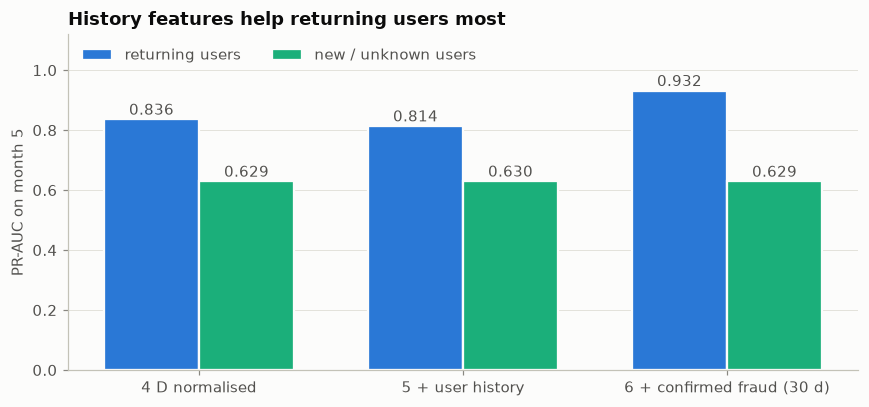

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(seg))
w = 0.36
for i, (col, color) in enumerate([("returning users", SERIES[0]), ("new / unknown users", SERIES[2])]):
    bars = ax.bar(x + (i - 0.5) * w, seg[col], width=w, color=color, label=col,
                  edgecolor="#fcfcfb", linewidth=1.5)
    label_bars(ax, bars, fmt="{:.3f}")
ax.set_xticks(x, seg.index)
ax.set_ylabel("PR-AUC on month 5")
ax.set_title("History features help returning users most")
ax.set_ylim(0, 1.12)
ax.legend(loc="upper left", ncols=2)
ax.grid(axis="x", visible=False)
finish(fig)

**Reading it.** Returning users make up 45 % of the validation month, and the model
already ranks them well (0.84). Confirmed fraud lifts them to 0.93. New and unknown
users are the hard part: PR-AUC ≈ 0.63, unchanged by any user feature, and their fraud
rate is **more than twice** that of returning users (4.6 % vs 2.0 %). Fraudsters favour
fresh identities. The next gains would come from linking new users to known ones through
shared devices, e-mails or addresses, i.e. graph features (project 4 goes there).

## 8. Which engineered features does the model use?

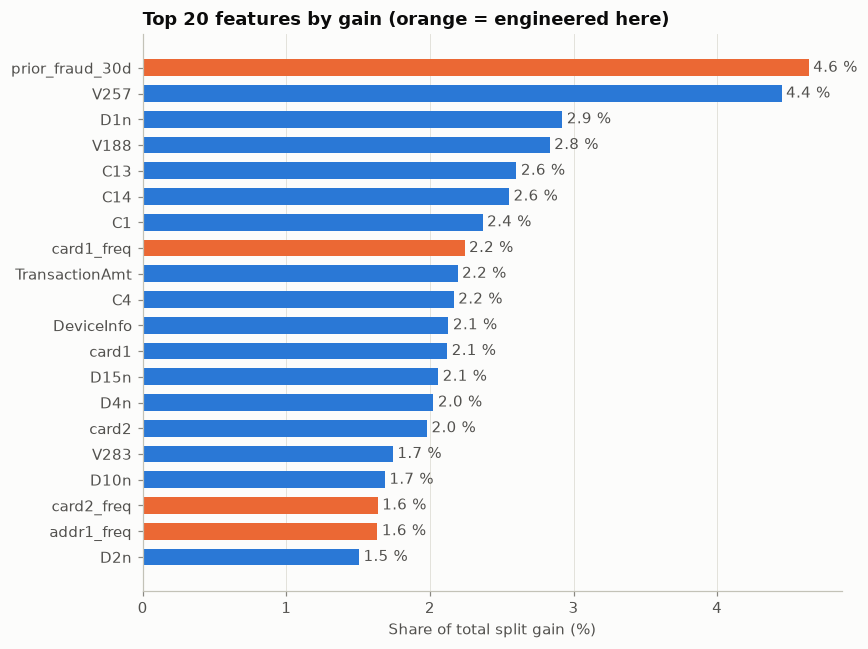

In [16]:
final_name = "6 + confirmed fraud (30 d)"
m = models[final_name]
imp = pd.Series(m.booster_.feature_importance("gain"), index=m.booster_.feature_name())
imp = imp / imp.sum()
engineered = set(amount_time + freq + history + ["prior_fraud_30d"])
top = imp.nlargest(20)[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(top.index, top.values * 100, height=0.65,
               color=[SERIES[1] if f in engineered else SERIES[0] for f in top.index])
label_bars(ax, bars, fmt="{:.1f} %", horizontal=True)
ax.set_xlabel("Share of total split gain (%)")
ax.set_title("Top 20 features by gain (orange = engineered here)")
ax.grid(axis="y", visible=False)
finish(fig)

**Reading it.** The confirmed-fraud count is the single most used feature, followed by
Vesta's V257 and our normalised account date `D1n`. Frequency encodings of card and
address appear in the top 20. Gain importance is biased towards features used in many
splits and isn't a causal statement; notebook 03 uses SHAP for a more careful view.

## 9. Conclusions

| Step | Effect on month-5 PR-AUC | Keep? |
|---|---|---|
| Frequency encodings | +0.012 | ✔ |
| Normalised D columns | +0.026 | ✔ |
| Amount & time | −0.005 | ✘ redundant with Vesta's columns |
| Causal user history | −0.006 | ✘ redundant with Vesta's columns |
| Confirmed fraud (30-day delay) | +0.053 | ✔ |
| Pruned set (the three ✔ groups) | 0.718, tied with the full set | ✔ carried to notebook 03 |

* **The user ID is the key idea.** It powers the strongest feature (confirmed fraud) even
  though its history aggregates were redundant here.
* **Label delay is a first-class design parameter.** Faster feedback is worth more than
  most feature engineering.
* **Leakage corrupts decisions, not just scores.** Whole-history aggregates looked
  helpful; their honest version isn't.
* **New users are the open problem**: twice the fraud rate and no history.

One refinement follows in notebook 03: `D3` (days since the previous transaction) is kept
raw, because normalising it produces a disguised calendar date.

**Next:** [03 · Models, validation over time and explanations](03_models_and_validation.ipynb)